In this notebook, we explore the application of deep learning techniques to predict real estate prices using artificial neural networks. The dataset utilized contains detailed information on house sales in King County, USA, covering transactions from May 2014 to May 2015. Each record includes various property attributes such as the number of bedrooms and bathrooms, square footage of living areas and lots, property conditions, geographic coordinates, and historical renovation details.

We begin by performing exploratory data analysis (EDA) to understand the underlying patterns and distributions within the dataset. Subsequently, we preprocess the data to prepare it for modeling. Finally, we construct and train neural network models to accurately estimate house prices based on the provided features. This notebook serves as a comprehensive guide for leveraging deep learning methodologies in real estate price prediction tasks.

- **Project Objective:**  
In this project, we will predict real estate prices using artificial neural networks.

- **Dataset Information:**  
Dataset includes house sale prices for King County in the USA and homes that were sold in the time period between May 2014 and May 2015.

- **Columns:**
  - `id`: Notation for a house
  - `date`: Date house was sold
  - `price`: Price is the prediction target
  - `bedrooms`: Number of bedrooms per house
  - `bathrooms`: Number of bathrooms per house
  - `sqft_living`: Square footage of the home
  - `qft_lot`: Square footage of the lot
  - `floors`: Total floors (levels) in the house
  - `waterfront`: House which has a view to a waterfront
  - `view`: Has been viewed
  - `condition`: How good the condition is
  - `grade`: Overall grade given to the housing unit, based on King County grading system
  - `sqft_abovesquare`: Footage of house apart from basement
  - `sqft_basement`: Square footage of the basement
  - `yr_built`: Built year
  - `yr_renovated`: Year when the house was renovated
  - `zipcode`: ZIP code
  - `lat`: Latitude coordinate
  - `long`: Longitude coordinate
  - `sqft_living15`: Living room area in 2015 (implies some renovations)
  - `sqft_lot15`: Lot size area in 2015 (implies some renovations)





# Reading Data

In [1]:
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings('ignore')


# EDA

In [2]:
df = pd.read_csv("/kaggle/input/real-estate-prices-2015/realestate_prices.csv")
df

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


In [3]:
df["date"] = pd.to_datetime(df["date"], format="%Y%m%dT%H%M%S")


In [4]:
df["building_age"] = 2015 - df["yr_built"]  # Use the current year

df["renovation_age"] = df["yr_renovated"].apply(lambda x: 0 if x == 0 else 2015 - x)  # Use the current year



In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id              21613 non-null  int64         
 1   date            21613 non-null  datetime64[ns]
 2   price           21613 non-null  float64       
 3   bedrooms        21613 non-null  int64         
 4   bathrooms       21613 non-null  float64       
 5   sqft_living     21613 non-null  int64         
 6   sqft_lot        21613 non-null  int64         
 7   floors          21613 non-null  float64       
 8   waterfront      21613 non-null  int64         
 9   view            21613 non-null  int64         
 10  condition       21613 non-null  int64         
 11  grade           21613 non-null  int64         
 12  sqft_above      21613 non-null  int64         
 13  sqft_basement   21613 non-null  int64         
 14  yr_built        21613 non-null  int64         
 15  yr

In [6]:
df1 = df.drop(columns=["date", "id", "zipcode", "lat", "long", "yr_built", "yr_renovated"], axis=1)
df_des = df1.describe().T
df_skew = df1.skew().to_frame("Skew")
df_kurt = df1.kurtosis().to_frame("Kurtosis")
describe = pd.concat([df_des, df_kurt, df_skew], axis=1)

describe

,count,mean,std,min,25%,50%,75%,max,Kurtosis,Skew
price,21613.0,540088.141767,367127.196483,75000.0,321950.00,450000.00,645000.0,7700000.0,34.585540,4.024069
bedrooms,21613.0,3.370842,0.930062,0.0,3.00,3.00,4.0,33.0,49.063653,1.974300
bathrooms,21613.0,2.114757,0.770163,0.0,1.75,2.25,2.5,8.0,1.279902,0.511108
sqft_living,21613.0,2079.899736,918.440897,290.0,1427.00,1910.00,2550.0,13540.0,5.243093,1.471555
sqft_lot,21613.0,15106.967566,41420.511515,520.0,5040.00,7618.00,10688.0,1651359.0,285.077820,13.060019
floors,21613.0,1.494309,0.539989,1.0,1.00,1.50,2.0,3.5,-0.484723,0.616177
waterfront,21613.0,0.007542,0.086517,0.0,0.00,0.00,0.0,1.0,127.632494,11.385108
view,21613.0,0.234303,0.766318,0.0,0.00,0.00,0.0,4.0,10.893022,3.395750
condition,21613.0,3.409430,0.650743,1.0,3.00,3.00,4.0,5.0,0.525764,1.032805
grade,21613.0,7.656873,1.175459,1.0,7.00,7.00,8.0,13.0,1.190932,0.771103


# data Visualization

<Axes: >

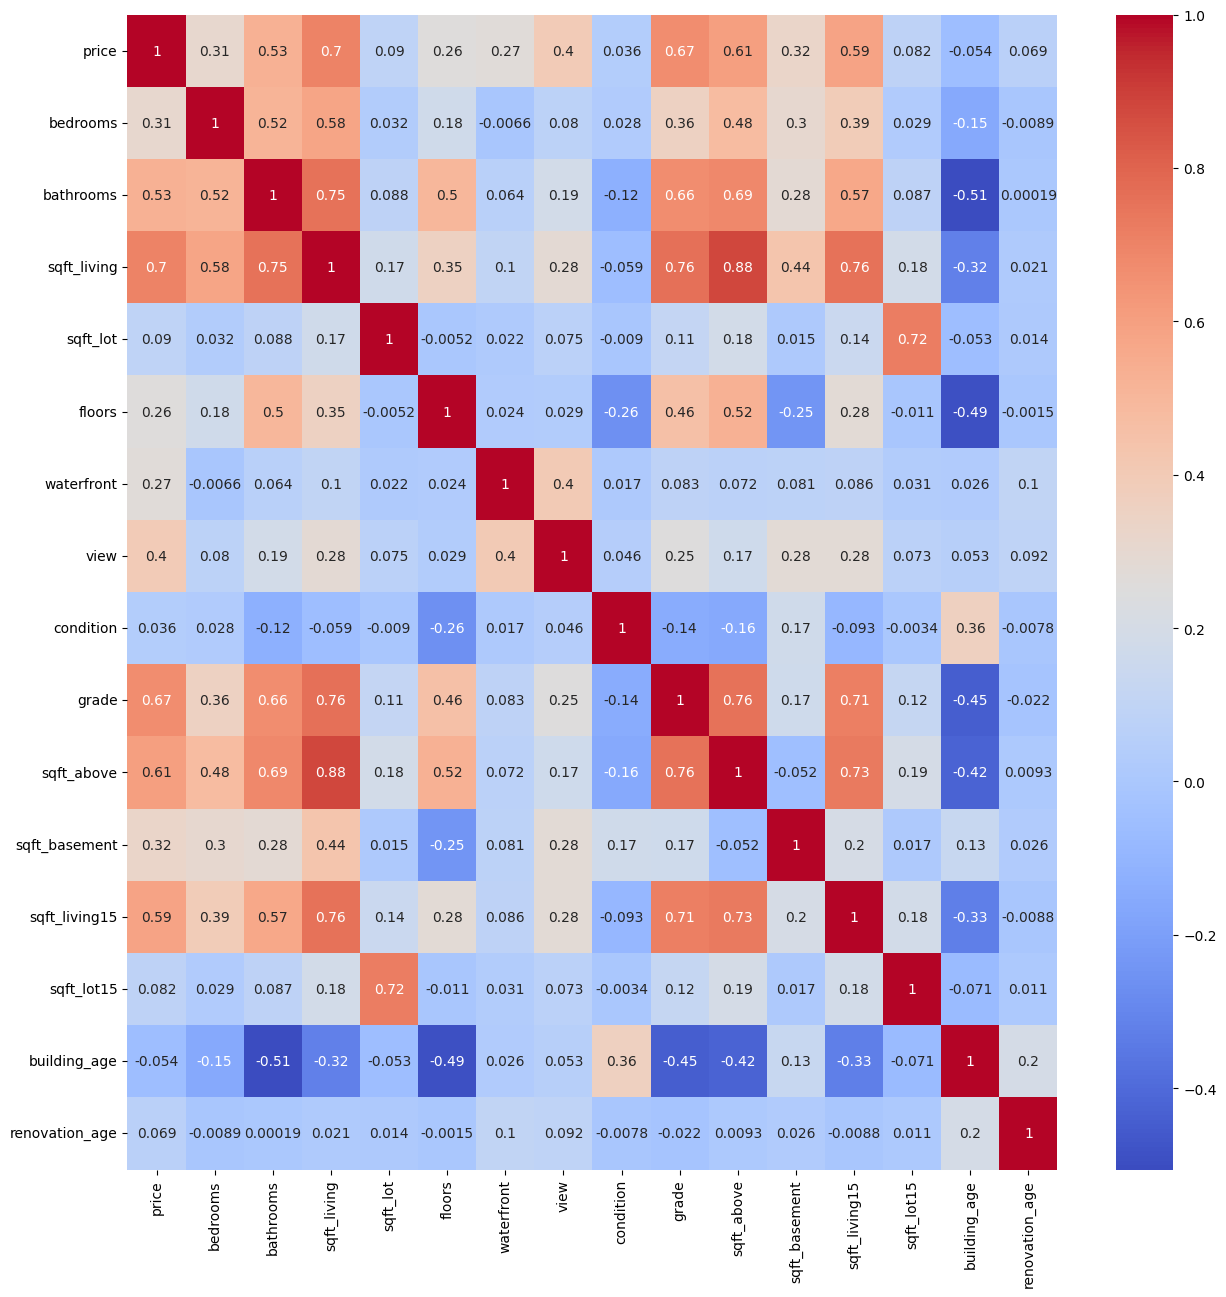

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 15))

sns.heatmap(df1.corr(), annot=True, cmap="coolwarm")

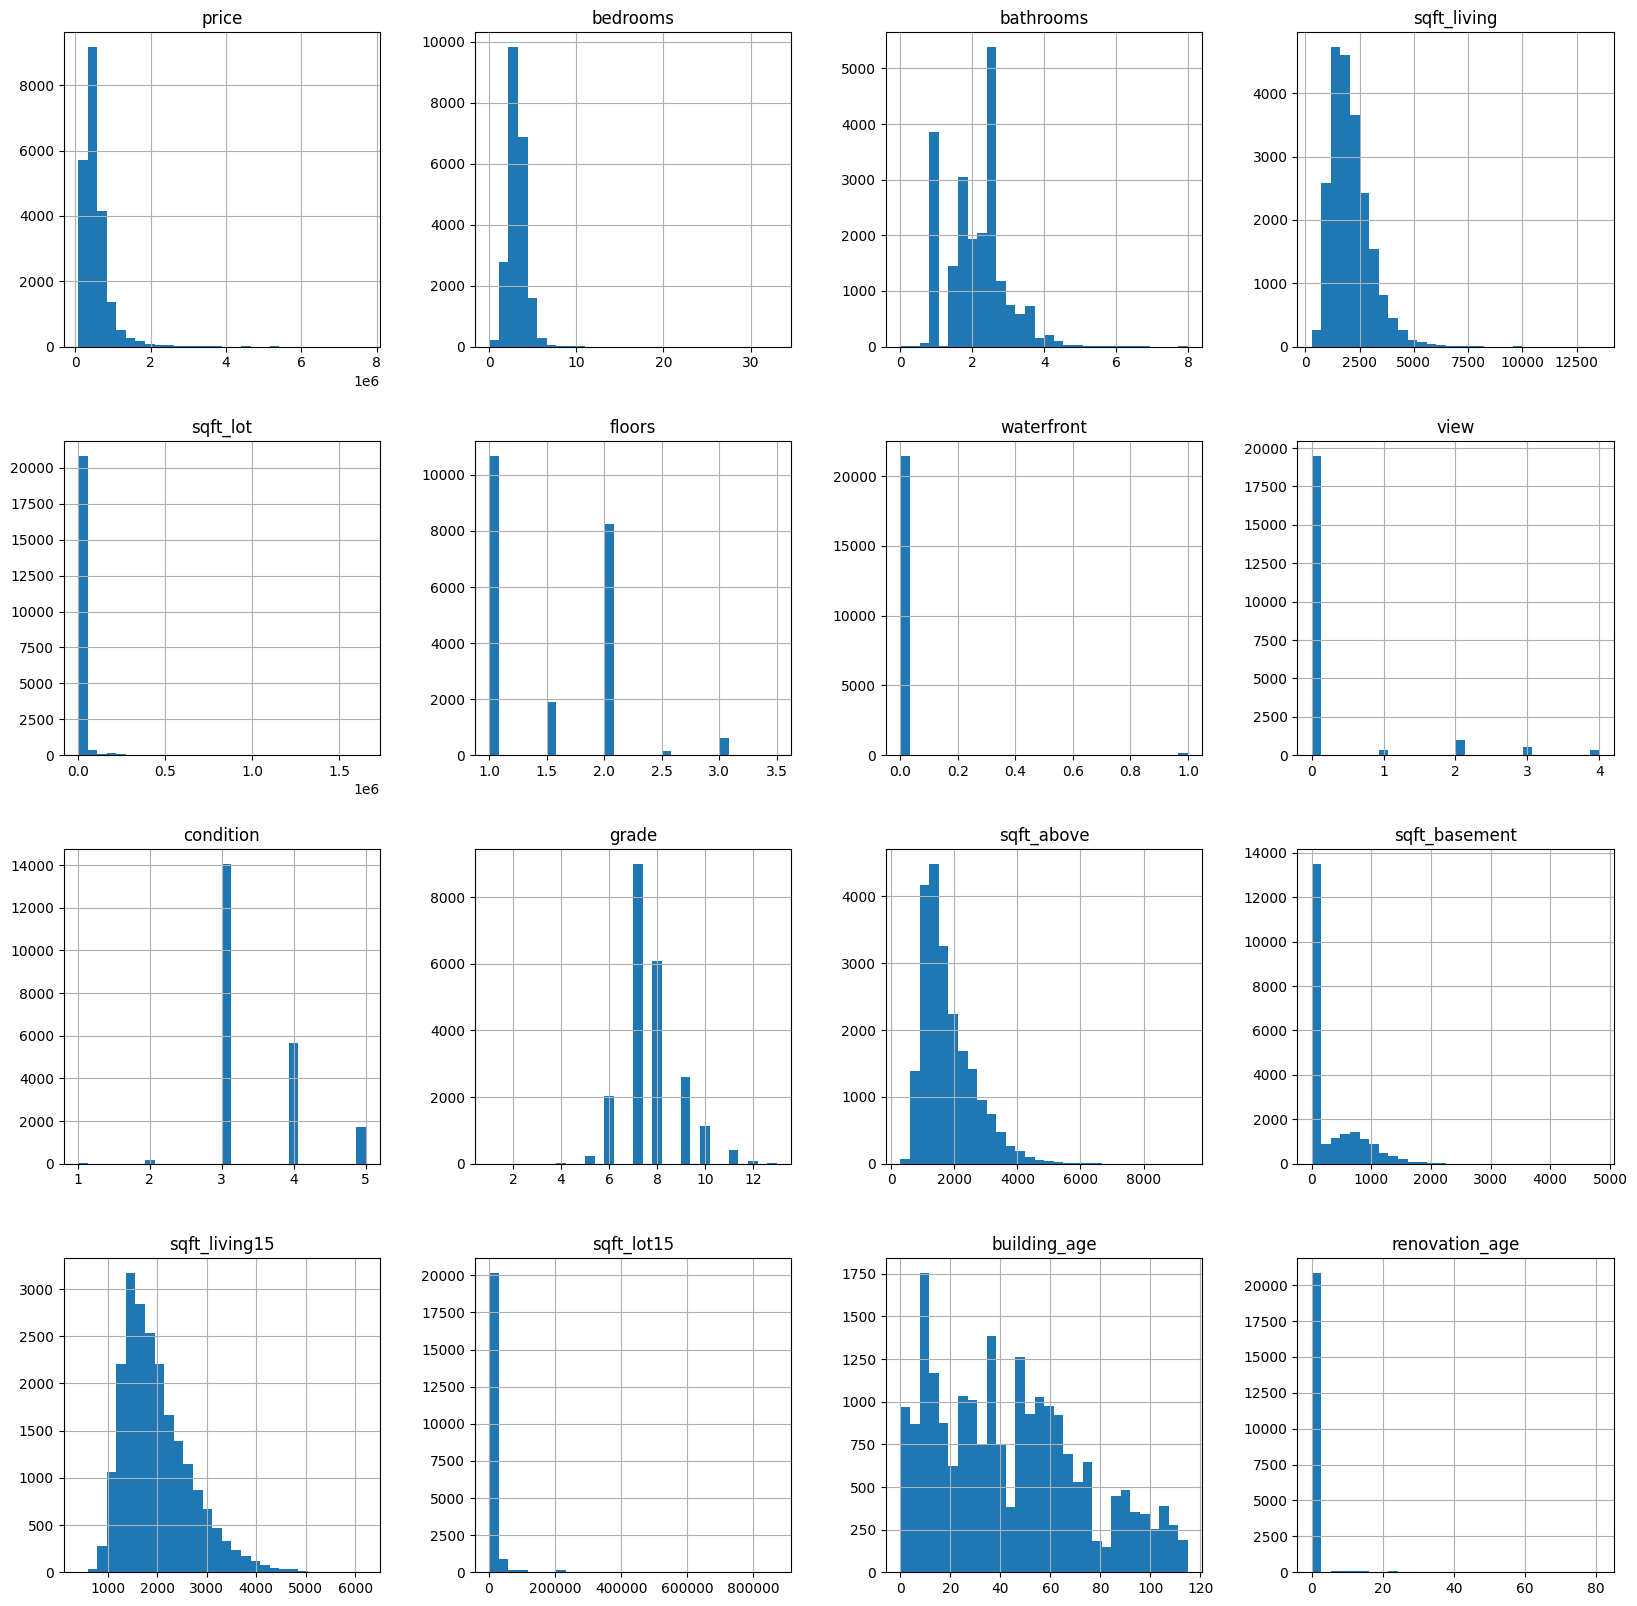

In [8]:
df1.hist(bins=30, figsize=(20, 20))

plt.show()

In [9]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   price           21613 non-null  float64
 1   bedrooms        21613 non-null  int64  
 2   bathrooms       21613 non-null  float64
 3   sqft_living     21613 non-null  int64  
 4   sqft_lot        21613 non-null  int64  
 5   floors          21613 non-null  float64
 6   waterfront      21613 non-null  int64  
 7   view            21613 non-null  int64  
 8   condition       21613 non-null  int64  
 9   grade           21613 non-null  int64  
 10  sqft_above      21613 non-null  int64  
 11  sqft_basement   21613 non-null  int64  
 12  sqft_living15   21613 non-null  int64  
 13  sqft_lot15      21613 non-null  int64  
 14  building_age    21613 non-null  int64  
 15  renovation_age  21613 non-null  int64  
dtypes: float64(3), int64(13)
memory usage: 2.6 MB


<Figure size 1500x1500 with 0 Axes>

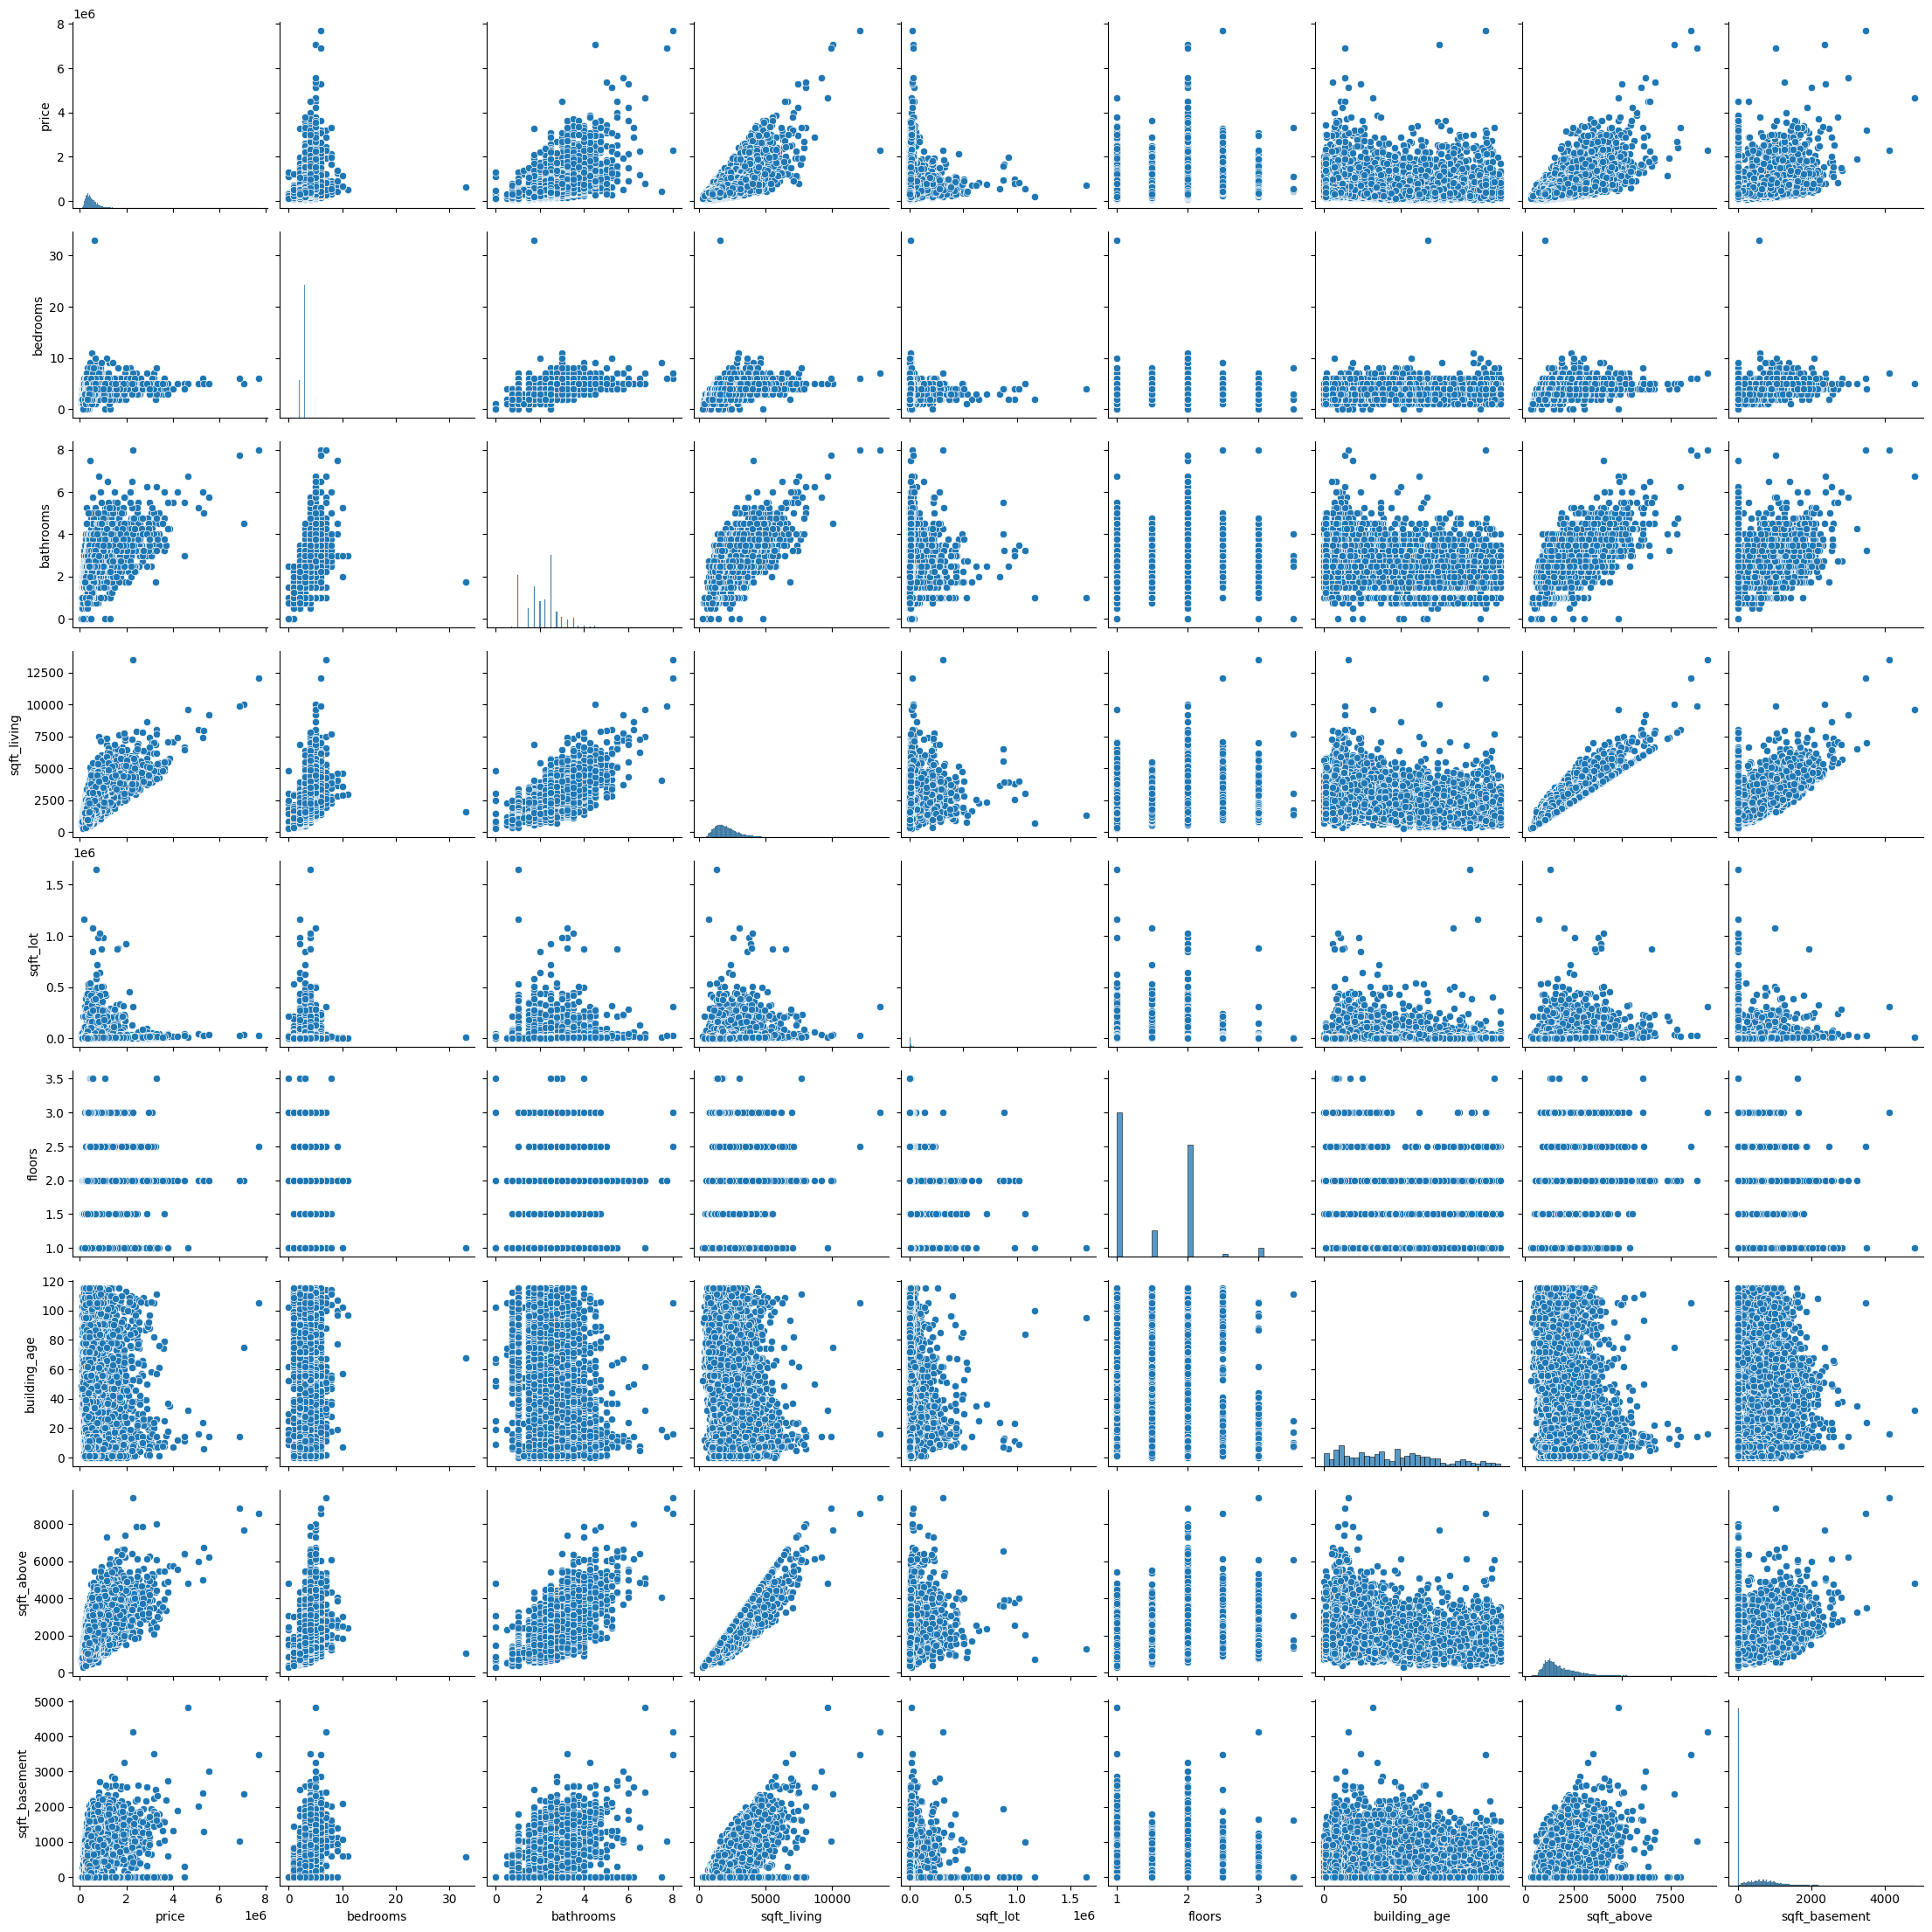

In [10]:
pairplot_data = [ "price","bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "building_age", "sqft_above", "sqft_basement"]

plt.figure(figsize=(15, 15))
sns.pairplot(df1[pairplot_data])
plt.show()

In [11]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   price           21613 non-null  float64
 1   bedrooms        21613 non-null  int64  
 2   bathrooms       21613 non-null  float64
 3   sqft_living     21613 non-null  int64  
 4   sqft_lot        21613 non-null  int64  
 5   floors          21613 non-null  float64
 6   waterfront      21613 non-null  int64  
 7   view            21613 non-null  int64  
 8   condition       21613 non-null  int64  
 9   grade           21613 non-null  int64  
 10  sqft_above      21613 non-null  int64  
 11  sqft_basement   21613 non-null  int64  
 12  sqft_living15   21613 non-null  int64  
 13  sqft_lot15      21613 non-null  int64  
 14  building_age    21613 non-null  int64  
 15  renovation_age  21613 non-null  int64  
dtypes: float64(3), int64(13)
memory usage: 2.6 MB


In [12]:
selected = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot","floors", "sqft_above", "sqft_basement"]

In [13]:
X = df1[selected]
X.shape

(21613, 7)

In [14]:
y = df1["price"]
y.shape

(21613,)

In [15]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X) 

X_scaled


array([[0.09090909, 0.125     , 0.06716981, ..., 0.        , 0.09758772,
        0.        ],
       [0.09090909, 0.28125   , 0.17207547, ..., 0.4       , 0.20614035,
        0.08298755],
       [0.06060606, 0.125     , 0.03622642, ..., 0.        , 0.05263158,
        0.        ],
       ...,
       [0.06060606, 0.09375   , 0.05509434, ..., 0.4       , 0.08004386,
        0.        ],
       [0.09090909, 0.3125    , 0.09886792, ..., 0.4       , 0.14364035,
        0.        ],
       [0.06060606, 0.09375   , 0.05509434, ..., 0.4       , 0.08004386,
        0.        ]])

In [16]:
X_scaled.shape

(21613, 7)

In [17]:
y = y.values.reshape(-1, 1)
y_scaled = scaler.fit_transform(y)

y_scaled

array([[0.01926557],
       [0.06072131],
       [0.01377049],
       ...,
       [0.04289849],
       [0.04262295],
       [0.03278689]])

# Train the Deep Learning model for the Limited features

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.3, random_state=3)

X_train.shape, X_test.shape, y_train.shape, y_test.shape


((15129, 7), (6484, 7), (15129, 1), (6484, 1))

In [19]:
import tensorflow.keras  as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

model = Sequential()

model.add(Dense(100, input_dim=X_train.shape[1], activation='relu'))
# model.add(Dropout(.1))
model.add(Dense(100, activation='relu'))
# model.add(Dropout(.1))
model.add(Dense(100, activation='relu'))
# model.add(Dropout(.1))
model.add(Dense(200, activation='relu'))
# model.add(Dropout(.1))
model.add(Dense(1, activation='linear'))


In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 100)                 │             800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 100)                 │          10,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 100)                 │          10,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 200)                 │          20,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │             201 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 41,401 (161.72 KB)

 Trainable params: 41,401 (161.72 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(optimizer='Adam', loss= 'mean_squared_error')

In [22]:
ecpoche_hit = model.fit(X_train, y_train, epochs=100, batch_size= 50, validation_split=.2)

Epoch 1/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0014 - val_loss: 0.0012
Epoch 2/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0011 - val_loss: 0.0014
Epoch 3/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0011 - val_loss: 9.9367e-04
Epoch 4/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0010 - val_loss: 0.0010
Epoch 5/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0010 - val_loss: 9.6701e-04
Epoch 6/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0010 - val_loss: 9.9296e-04
Epoch 7/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0011 - val_loss: 0.0010
Epoch 8/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0010 - val_loss: 0.0010
Epoch 9/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0011 - val_loss: 9.7265e-04
Epoch 10/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0011 - val_loss: 9.6210e-04
Epoch 11/100
243/243 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 12/100
243/243 

## Evaluate the Deep Learning Model

In [23]:
ecpoche_hit.history.keys()

dict_keys(['loss', 'val_loss'])

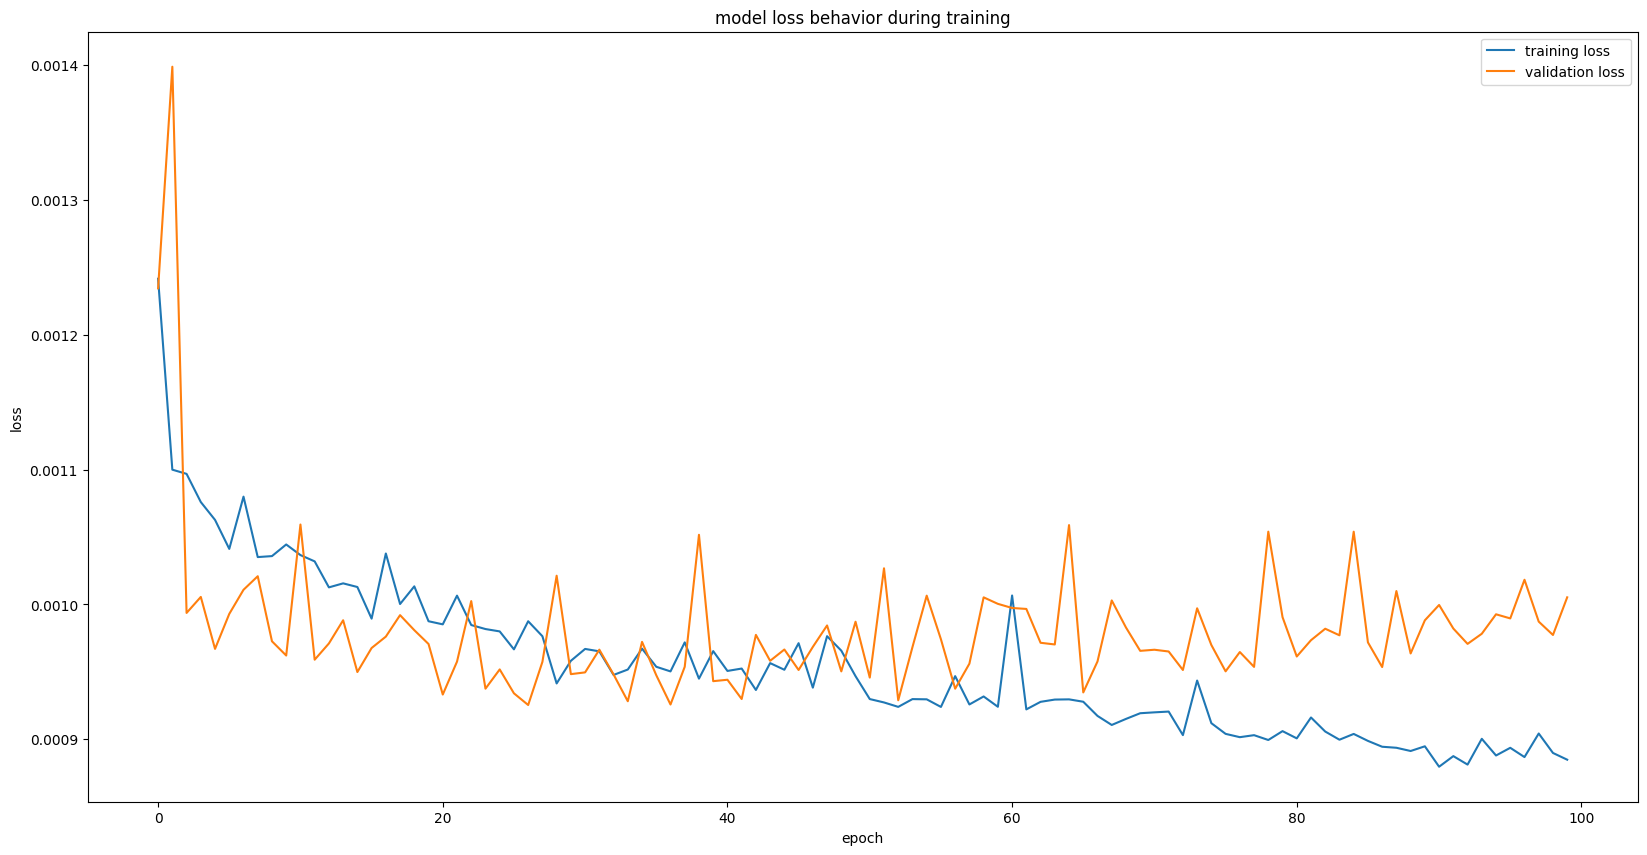

In [24]:
plt.figure(figsize=(20,10))
plt.plot(ecpoche_hit.history['loss'])

plt.plot(ecpoche_hit.history['val_loss'])

plt.title('model loss behavior during training')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['training loss', 'validation loss'])
plt.show();

203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


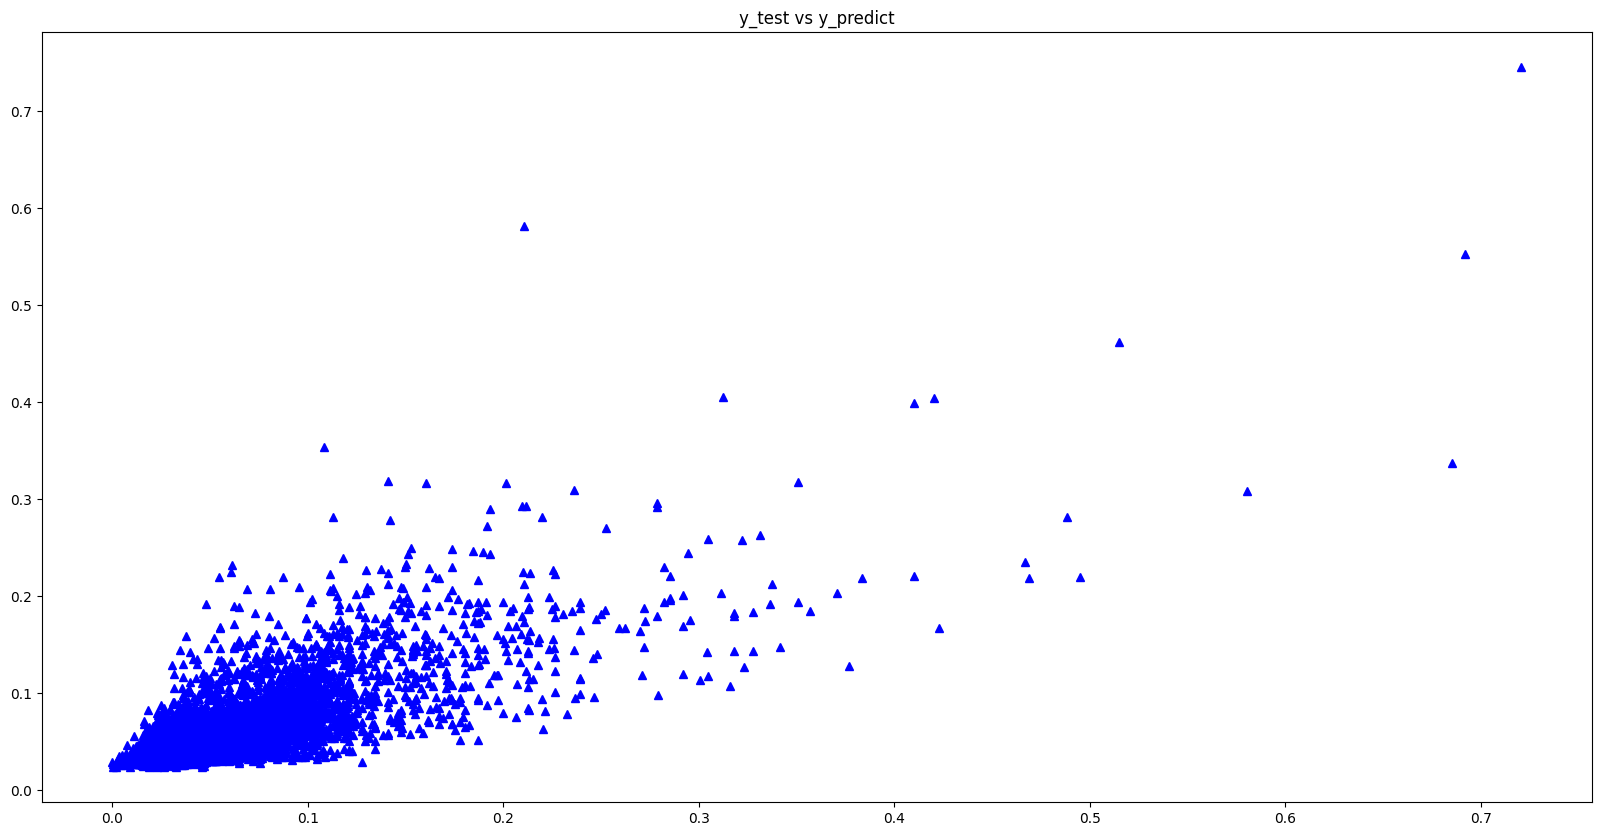

In [25]:
y_predict = model.predict(X_test)

plt.figure(figsize=(20,10))
plt.plot(y_test, y_predict, "^", color= "b")

plt.title('y_test vs y_predict')
plt.show();

## Lets try to predict on sample data

In [26]:
# Example test input: 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'sqft_above', 'sqft_basement'
X_test_1 = np.array([[4, 3, 1960, 5000, 1, 2000, 3000]])

# Scaling the input using MinMaxScaler
scaler_1 = MinMaxScaler()
X_test_scaled_1 = scaler_1.fit_transform(X_test_1)

# Predicting using the trained model
y_predict_1 = model.predict(X_test_scaled_1)

# Inverse transform to get the original scale of predictions
y_predict_1 = scaler.inverse_transform(y_predict_1)
print(y_predict_1) 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
[[266441.62]]


In [27]:
y_predict_orgi = scaler.inverse_transform(y_predict)

y_test_orgi = scaler.inverse_transform(y_test)

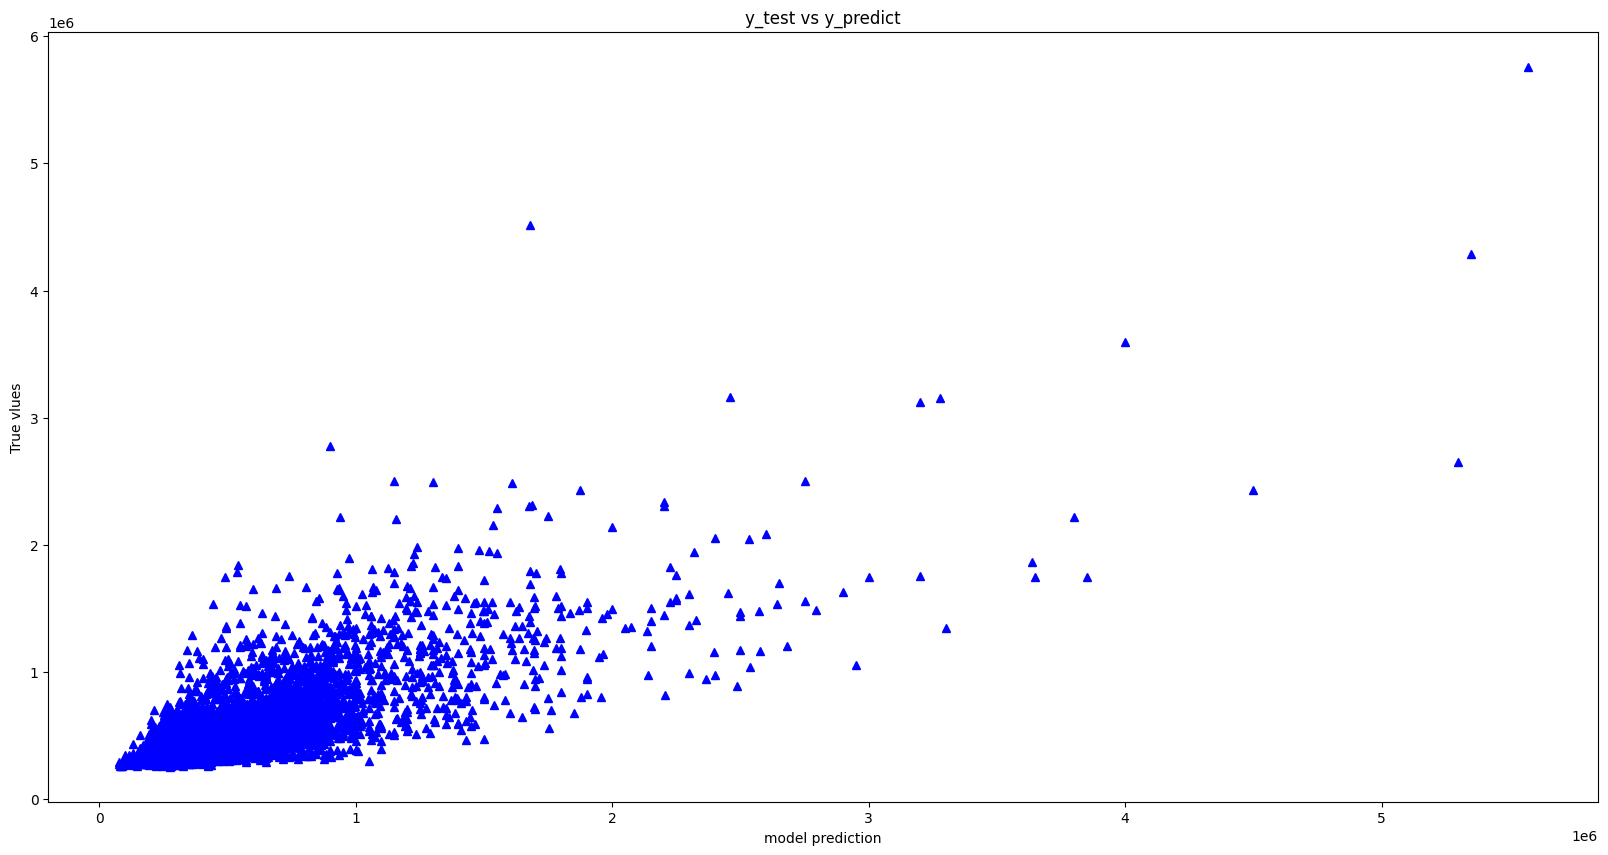

In [28]:
plt.figure(figsize=(20, 10))

plt.plot(y_test_orgi, y_predict_orgi, "^", color="b")

plt.title('y_test vs y_predict')
plt.xlabel("model prediction")
plt.ylabel('True vlues')

plt.show();

In [29]:
k = X_test.shape[1]
n = len(X_test)
n

6484

In [30]:

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from math import sqrt

RMSE = float(format(np.sqrt(mean_squared_error(y_test_orgi, y_predict_orgi)),'.3f'))
MSE = mean_squared_error(y_test_orgi, y_predict_orgi)
MAE = mean_absolute_error(y_test_orgi, y_predict_orgi)
r2 = r2_score(y_test_orgi, y_predict_orgi)
adj_r2 = 1-(1-r2)*(n-1)/(n-k-1)

print('RMSE =',RMSE, '\nMSE =',MSE, '\nMAE =',MAE, '\nR2 =', r2, '\nAdjusted R2 =', adj_r2) 

RMSE = 239089.523 
MSE = 57163800143.631325 
MAE = 156918.4981131439 
R2 = 0.5735376681040782 
Adjusted R2 = 0.5730766989374212


# DEEP LEARNING MODEL WITH INCREASED NUMBER OF FEATURES (INDEPENDANT VARIABLES)

In [31]:
selected_features = ['bedrooms','bathrooms','sqft_living','sqft_lot','floors', 'sqft_above', 'sqft_basement', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'yr_built', 
'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

X = df[selected_features]
X_scaled = scaler.fit_transform(X)

In [32]:
y = df['price']

In [33]:
y = y.values.reshape(-1,1)
y_scaled = scaler.fit_transform(y)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size = 0.25)

In [34]:
import tensorflow.keras as tf
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Dense

model = Sequential()
model.add(Dense(10, input_dim = 19, activation = 'relu'))
model.add(Dense(10, activation = 'relu'))

model.add(Dense(200, activation ='relu'))
model.add(Dense(200, activation ='relu'))
model.add(Dense(1, activation = 'linear'))


In [35]:
model.compile(optimizer = 'adam', loss = 'mean_squared_error')

In [36]:
epochs_hist = model.fit(X_train, y_train, epochs = 100, batch_size = 50, verbose = 1, validation_split = 0.2)

Epoch 1/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0025 - val_loss: 0.0011
Epoch 2/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 7.6799e-04 - val_loss: 8.1267e-04
Epoch 3/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 7.0062e-04 - val_loss: 7.7847e-04
Epoch 4/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6.1354e-04 - val_loss: 6.4335e-04
Epoch 5/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 5.7210e-04 - val_loss: 6.1543e-04
Epoch 6/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 5.5622e-04 - val_loss: 5.5462e-04
Epoch 7/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 4.8171e-04 - val_loss: 6.4520e-04
Epoch 8/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 5.2445e-04 - val_loss: 5.2404e-04
Epoch 9/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 4.7551e-04 - val_loss: 5.7330e-04
Epoch 10/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 5.1806e-04 - val_loss: 5.0912e-04
Epoch 11/100
260/260 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - l

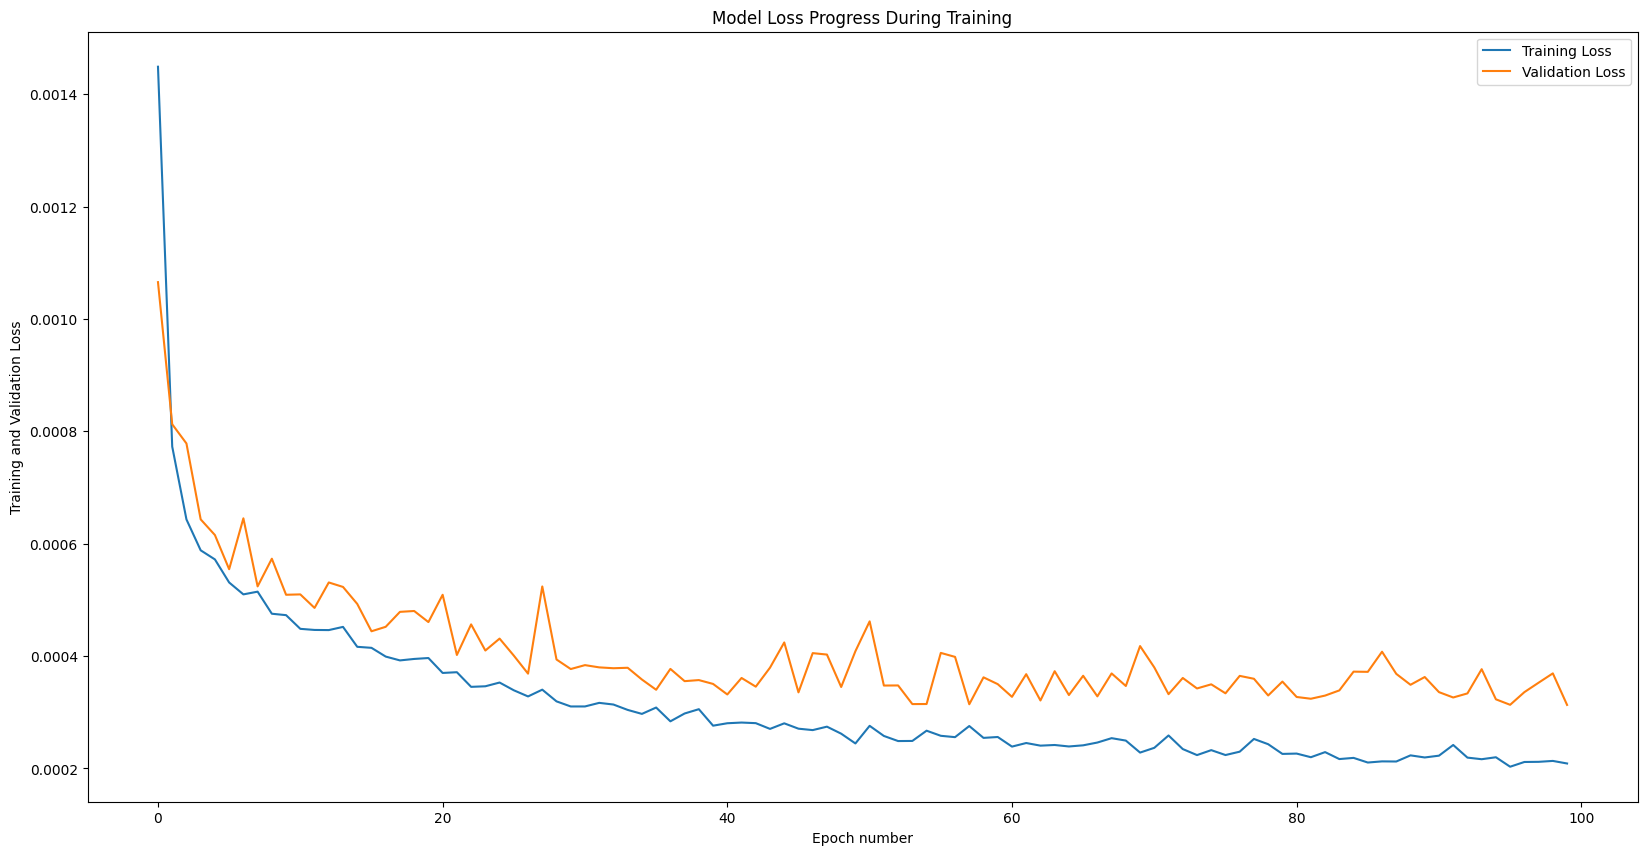

In [37]:
plt.figure(figsize=(20, 10))
plt.plot(epochs_hist.history['loss'])
plt.plot(epochs_hist.history['val_loss'])
plt.title('Model Loss Progress During Training')
plt.ylabel('Training and Validation Loss')
plt.xlabel('Epoch number')
plt.legend(['Training Loss', 'Validation Loss'])

169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


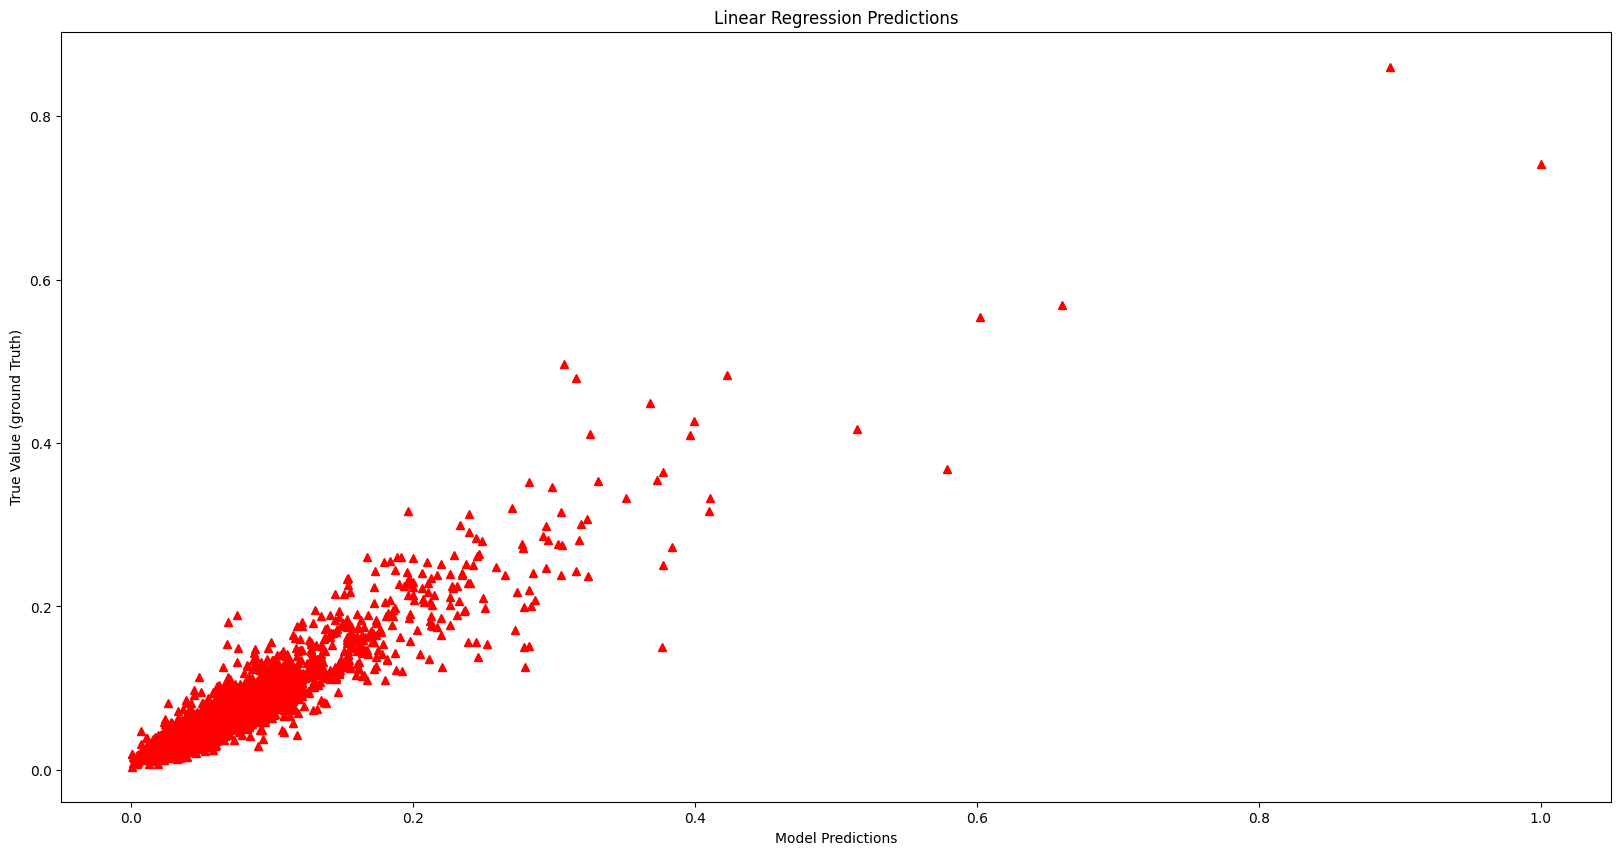

In [38]:

y_predict = model.predict(X_test)

plt.figure(figsize=(20, 10))
plt.plot(y_test, y_predict, "^", color = 'r')
plt.xlabel("Model Predictions")
plt.ylabel("True Value (ground Truth)")
plt.title('Linear Regression Predictions')
plt.show()

In [39]:
y_predict_orig = scaler.inverse_transform(y_predict)
y_test_orig = scaler.inverse_transform(y_test)


In [40]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from math import sqrt

RMSE = float(format(np.sqrt(mean_squared_error(y_test_orig, y_predict_orig)),'.3f'))
MSE = mean_squared_error(y_test_orig, y_predict_orig)
MAE = mean_absolute_error(y_test_orig, y_predict_orig)
r2 = r2_score(y_test_orig, y_predict_orig)
adj_r2 = 1-(1-r2)*(n-1)/(n-k-1)

print('RMSE =',RMSE, '\nMSE =',MSE, '\nMAE =',MAE, '\nR2 =', r2, '\nAdjusted R2 =', adj_r2) 


RMSE = 124520.796 
MSE = 15505428582.288502 
MAE = 71990.04134957901 
R2 = 0.8907987449680514 
Adjusted R2 = 0.8906807077868866
